# Ocular dominance: why did it change between the old and the new pRF fits?

- **Old**: `prfmodel_old`. prfmodel v1, common design (bars A), n stuck at 1 for many vertices, old screen scale.
- **New**: `prfmodel`. prfmodel v2, subject-specific designs, free n, new screen scale.

Same measures and vertex selection as `od_group_figure_v12.ipynb`: % of vertices preferring FE-LE, and weighted median of the vertex OD index; weight = mean pRF R² of the two eyes.

1. **Per subject**: old vs new, for every ROI. Which amblyopes lost their fellow-eye dominance?
2. **Decomposition**: is the change due to the **vertex selection** (other vertices kept / other weights) or to the **betas** (other OD values on the same vertices)? Each version's betas are crossed with each version's selection.
3. **Which eye's β changed**: β_FE and β_AE old vs new on common vertices, and pRF R² of each eye old vs new. In the GLM, the common regressor is the mean of the two eyes' pRF predictions, so a better fit of the AE can raise β_AE.
4. **Eccentricity**: OD vs eccentricity (positions of the new fit for both versions). Do the new fits add peripheral vertices with weaker dominance?
5. **Subjects without fellow-eye dominance**: detailed view.

Read only. Caches in `Desktop/fig_od/od_vertex_cache_old/` and `od_vertex_cache/`; the new cache is the one already built by v12.

In [1]:
# Stop warnings
import warnings
warnings.filterwarnings("ignore")

# General imports
import os
import sys
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# Personal imports
sys.path.append("{}/../../analysis_code/utils".format(os.getcwd()))
from settings_utils import load_settings
from pycortex_utils import set_pycortex_config_file, get_rois, load_surface_pycortex

In [2]:
# Directories
main_dir = '/Users/uriel/disks/meso_shared'
project_dir = 'amblyo7T_prf'
pp_dir = '{}/{}/derivatives/pp_data'.format(main_dir, project_dir)
fig_dir = '/Users/uriel/Desktop/fig_od'
versions = {'old': 'prfmodel_old', 'new': 'prfmodel'}
cache_dirs = {'old': '{}/od_vertex_cache_old'.format(fig_dir), 'new': '{}/od_vertex_cache'.format(fig_dir)}
for d in cache_dirs.values():
    os.makedirs(d, exist_ok=True)

# Settings
base_dir = os.path.abspath(os.path.join(os.getcwd(), "../../"))
settings = load_settings([os.path.join(base_dir, project_dir, f) for f in
                          ["settings.yml", "prf-analysis.yml", "figure-settings.yml"]])
analysis_info = settings[0]
patients = analysis_info['group-patient']
controls = analysis_info['group-control']
subjects = patients + controls
maps_names_css = analysis_info['maps_names_css']
maps_names_css_stats = analysis_info['maps_names_css_stats']
maps_names_css_od = analysis_info['maps_names_css_od']

task = 'BarsBarsRingsWedges'
file_spec = '{}/{}/fsnative/{}/prf_derivatives/{}_task-{}{}_hemi-{}_fmriprep_dct_psc_concat_prf-css_{}.func.gii'
rois_to_keep = ['V1', 'V2', 'V3', 'V4', 'V3A', 'V3B', 'LO1', 'LO2']
eyes = {'L': 'LeftEye', 'R': 'RightEye'}

ecc_th = analysis_info['ecc_th']
size_th = analysis_info['size_th']
n_th = analysis_info['n_th']
rsqr_th = analysis_info['rsqr_th']
amp_th = analysis_info['prf_amp_th']
amp_th = amp_th['psc'] if isinstance(amp_th, dict) else amp_th
stats_th = analysis_info['stats_th']
p_name = 'corr_pvalue_5pt' if stats_th == 0.05 else 'corr_pvalue_1pt'

participants = pd.read_csv('{}/{}/participants.tsv'.format(main_dir, project_dir), sep='\t')
ambly_eye = {s: str(e).split(' ')[0] for s, e in zip(participants.participant_id, participants.amblyopic_eye)
             if str(e).split(' ')[0] in ('L', 'R')}

cortex_dir = '{}/{}/derivatives/pp_data/cortex'.format(main_dir, project_dir)
set_pycortex_config_file(cortex_dir)

In [3]:
# Same helpers and vertex selection as od_group_figure_v12.ipynb
deriv_keys = ['prf_rsq', 'prf_ecc', 'prf_size', 'prf_n', 'amplitude', 'prf_x', 'prf_y']


def wmedian(x, w):
    x, w = np.asarray(x, float), np.asarray(w, float)
    ok = np.isfinite(x) & np.isfinite(w) & (w > 0)
    if ok.sum() == 0:
        return np.nan
    o = np.argsort(x[ok])
    cw = np.cumsum(w[ok][o])
    return x[ok][o][np.searchsorted(cw, 0.5 * cw[-1])]


def od_index(b_fe, b_ae):
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where((b_fe > 0) & (b_ae > 0), (b_fe - b_ae) / (b_fe + b_ae), np.nan)


def pref_percent(b_a, b_b, w):
    return 100 * np.sum(w * (b_a > b_b)) / np.sum(w) if np.sum(w) > 0 else np.nan


def select(d, p):
    with np.errstate(invalid='ignore'):
        return ((d['prf_ecc'] >= ecc_th[0]) & (d['prf_ecc'] <= ecc_th[1])
                & (d['prf_size'] >= size_th[0]) & (d['prf_size'] <= size_th[1])
                & (d['prf_n'] >= n_th[0]) & (d['prf_n'] <= n_th[1])
                & (d['prf_rsq'] >= rsqr_th)
                & (d['amplitude'] >= amp_th[0]) & (d['amplitude'] <= amp_th[1]) & (d['amplitude'] > 0)
                & (p <= stats_th))


def load_subject(subject, version):
    """Same content and cache format as v12 (cache of the new version = cache built by v12)."""
    folder = versions[version]
    fns = [file_spec.format(pp_dir, subject, folder, subject, task, '', h, 'od') for h in ['L', 'R']]
    for eye in eyes.values():
        for kind in ['deriv', 'stats']:
            fns += [file_spec.format(pp_dir, subject, folder, subject, task, eye, h, kind) for h in ['L', 'R']]
    if not all(os.path.isfile(fn) for fn in fns):
        return None
    cache_fn = '{}/{}_od-vertex-cache.npz'.format(cache_dirs[version], subject)
    src_mtime = max(os.path.getmtime(fn) for fn in fns)
    if not (os.path.isfile(cache_fn) and float(np.load(cache_fn)['src_mtime']) >= src_mtime):
        od_mat = load_surface_pycortex(L_fn=fns[0], R_fn=fns[1])['data_concat']
        rois = get_rois(subject=subject, surf_format='fsnative', rois_type='rois-mmp', mask=True, rois=None, hemis=None)
        idx = np.where(np.any([rois[roi] for roi in rois_to_keep], axis=0))[0]
        save = {'n_vertices': od_mat.shape[1], 'idx': idx, 'src_mtime': src_mtime,
                'beta_L': od_mat[maps_names_css_od.index('od_beta_le')][idx].astype(np.float32),
                'beta_R': od_mat[maps_names_css_od.index('od_beta_re')][idx].astype(np.float32)}
        for roi in rois_to_keep:
            save['roi_{}'.format(roi)] = rois[roi][idx]
        for e, eye in eyes.items():
            deriv = load_surface_pycortex(L_fn=file_spec.format(pp_dir, subject, folder, subject, task, eye, 'L', 'deriv'),
                                          R_fn=file_spec.format(pp_dir, subject, folder, subject, task, eye, 'R', 'deriv'))['data_concat']
            st = load_surface_pycortex(L_fn=file_spec.format(pp_dir, subject, folder, subject, task, eye, 'L', 'stats'),
                                       R_fn=file_spec.format(pp_dir, subject, folder, subject, task, eye, 'R', 'stats'))['data_concat']
            for key in deriv_keys:
                save['{}_{}'.format(e, key)] = deriv[maps_names_css.index(key)][idx].astype(np.float32)
            save['{}_p'.format(e)] = st[maps_names_css_stats.index(p_name)][idx].astype(np.float32)
        np.savez_compressed(cache_fn, **save)
        print('{} {}: read from the data disks, cached'.format(subject, version))
    c = np.load(cache_fn)
    out = {'idx': c['idx'], 'beta': {e: c['beta_{}'.format(e)].astype(float) for e in eyes},
           'd': {e: {k: c['{}_{}'.format(e, k)].astype(float) for k in deriv_keys} for e in eyes},
           'p': {e: c['{}_p'.format(e)].astype(float) for e in eyes},
           'rois': {roi: c['roi_{}'.format(roi)].astype(bool) for roi in rois_to_keep}}
    out['keep_eye'] = {e: select(out['d'][e], out['p'][e]) & np.isfinite(out['beta'][e]) for e in eyes}
    out['keep'] = out['keep_eye']['L'] & out['keep_eye']['R']
    out['w'] = np.nan_to_num(np.clip(np.nanmean([out['d']['L']['prf_rsq'], out['d']['R']['prf_rsq']], axis=0), 0, None))
    return out

data = {}
for subject in subjects:
    data[subject] = {v: load_subject(subject, v) for v in versions}
    if any(data[subject][v] is None for v in versions):
        print('{}: missing files, skipped'.format(subject))
        data.pop(subject)
for subject in data:
    assert np.array_equal(data[subject]['old']['idx'], data[subject]['new']['idx']), subject
print('{} subjects loaded'.format(len(data)))

sub-01 old: read from the data disks, cached
sub-02 old: read from the data disks, cached
sub-03 old: read from the data disks, cached
sub-04 old: read from the data disks, cached
sub-05 old: read from the data disks, cached
sub-06 old: read from the data disks, cached
sub-08 old: read from the data disks, cached
sub-09 old: read from the data disks, cached
sub-10 old: read from the data disks, cached
sub-11 old: read from the data disks, cached
sub-12 old: read from the data disks, cached
sub-13 old: read from the data disks, cached
sub-14 old: read from the data disks, cached
sub-16 old: read from the data disks, cached
sub-17 old: read from the data disks, cached
sub-18 old: read from the data disks, cached
sub-19 old: read from the data disks, cached
sub-20 old: read from the data disks, cached
sub-21 old: read from the data disks, cached
19 subjects loaded


## 1. Old vs new, per subject and ROI

In [4]:
def fe_ae(subject):
    return ('R', 'L') if ambly_eye.get(subject) == 'L' else ('L', 'R')


def measures(beta_v, sel_v, subject, roi):
    """OD measures with the betas of version beta_v and the vertex selection / weights of version sel_v."""
    fe, ae = fe_ae(subject)
    B, S = data[subject][beta_v], data[subject][sel_v]
    m = S['rois'][roi] & S['keep'] & np.isfinite(B['beta'][fe]) & np.isfinite(B['beta'][ae])
    w = S['w'][m]
    if m.sum() < 10 or w.sum() == 0:
        return np.nan, np.nan, int(m.sum())
    b_fe, b_ae = B['beta'][fe][m], B['beta'][ae][m]
    return pref_percent(b_fe, b_ae, w), wmedian(od_index(b_fe, b_ae), w), int(m.sum())

rows = []
for subject in data:
    group = 'patient' if subject in patients else 'control'
    fe, ae = fe_ae(subject)
    for roi in rois_to_keep:
        rec = {'subject': subject, 'group': group, 'roi': roi}
        for bv in versions:
            for sv in versions:
                p, o, n = measures(bv, sv, subject, roi)
                rec['pref betas-{} sel-{}'.format(bv, sv)] = p
                rec['od betas-{} sel-{}'.format(bv, sv)] = o
                rec['n sel-{}'.format(sv)] = n
        for v in versions:
            D = data[subject][v]
            m = D['rois'][roi] & D['keep']
            rec['rsq_fe {}'.format(v)] = np.nanmedian(D['d'][fe]['prf_rsq'][m]) if m.any() else np.nan
            rec['rsq_ae {}'.format(v)] = np.nanmedian(D['d'][ae]['prf_rsq'][m]) if m.any() else np.nan
        rows.append(rec)
df = pd.DataFrame(rows)
df['pref old'], df['pref new'] = df['pref betas-old sel-old'], df['pref betas-new sel-new']
df['od old'], df['od new'] = df['od betas-old sel-old'], df['od betas-new sel-new']

pat = df[df.group == 'patient']
print('Amblyopes, median over subjects: old -> new')
print(pat.groupby('roi')[['pref old', 'pref new', 'od old', 'od new', 'n sel-old', 'n sel-new']].median()
      .reindex(rois_to_keep).round(3).to_string())
print('\nV1, per amblyope (FE dominance lost if pref new < 55 % or od new < 0.02):')
v1 = pat[pat.roi == 'V1'][['subject', 'pref old', 'pref new', 'od old', 'od new', 'n sel-old', 'n sel-new',
                           'rsq_fe old', 'rsq_ae old', 'rsq_fe new', 'rsq_ae new']]
print(v1.round(3).to_string(index=False))

Amblyopes, median over subjects: old -> new
     pref old  pref new  od old  od new  n sel-old  n sel-new
roi                                                          
V1     58.049    57.805   0.019   0.020     4403.0     5385.0
V2     65.192    63.862   0.086   0.084     4280.0     5520.0
V3     70.794    71.518   0.136   0.132     2951.0     3714.0
V4     70.755    70.698   0.103   0.102     2470.0     2906.0
V3A    70.972    70.224   0.143   0.126      895.0     1285.0
V3B    83.327    81.659   0.121   0.120      516.0      611.0
LO1    76.240    76.963   0.136   0.136      448.0      544.0
LO2    67.965    66.974   0.124   0.126      321.0      359.0

V1, per amblyope (FE dominance lost if pref new < 55 % or od new < 0.02):
subject  pref old  pref new  od old  od new  n sel-old  n sel-new  rsq_fe old  rsq_ae old  rsq_fe new  rsq_ae new
 sub-01    57.375    56.407   0.013   0.012       7446       8611       0.153       0.204       0.116       0.151
 sub-02    73.610    73.332   0.0

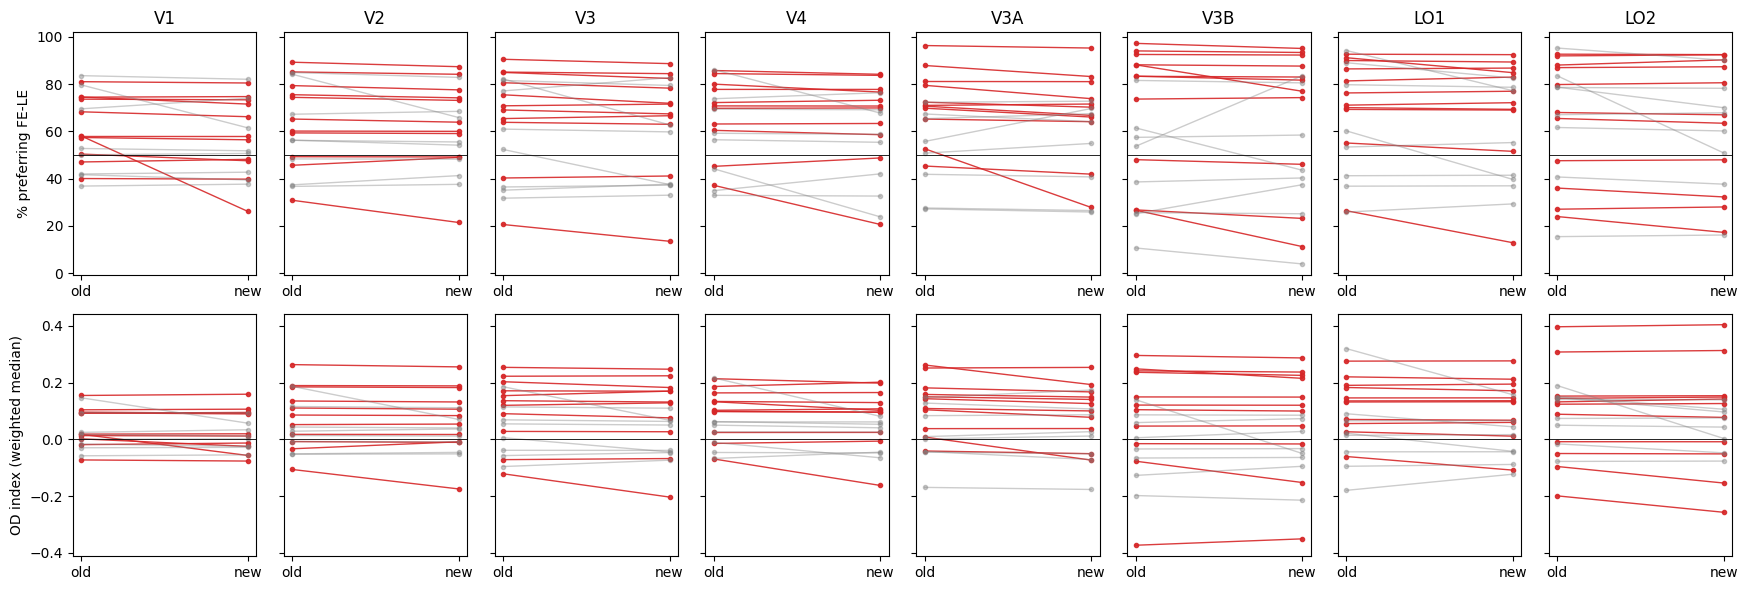

In [5]:
fig, axes = plt.subplots(2, len(rois_to_keep), figsize=(2.2 * len(rois_to_keep), 6), sharey='row')
for j, roi in enumerate(rois_to_keep):
    for i, (meas, h0) in enumerate([('pref', 50), ('od', 0)]):
        ax = axes[i, j]
        d = df[df.roi == roi]
        for _, r in d.iterrows():
            col = 'tab:red' if r.group == 'patient' else 'grey'
            ax.plot([0, 1], [r['{} old'.format(meas)], r['{} new'.format(meas)]], '-o', color=col, ms=3, lw=1,
                    alpha=0.9 if r.group == 'patient' else 0.4)
        ax.axhline(h0, color='k', lw=0.6)
        ax.set_xticks([0, 1]); ax.set_xticklabels(['old', 'new'])
        if i == 0: ax.set_title(roi)
axes[0, 0].set_ylabel('% preferring FE-LE')
axes[1, 0].set_ylabel('OD index (weighted median)')
plt.tight_layout()
fig.savefig('{}/od_change_per_subject.pdf'.format(fig_dir), bbox_inches='tight')
plt.show()

## 2. Decomposition: vertex selection or betas?

For each amblyope and ROI, the 4 combinations: betas old/new × selection-weights old/new.
- **Effect of the betas** (same vertices, other OD values) = mean over the two selections of (betas new − betas old).
- **Effect of the selection** (same betas, other vertices / weights) = mean over the two beta versions of (selection new − selection old).

In [6]:
for meas in ['pref', 'od']:
    a = '{} betas-{} sel-{}'
    pat = df[df.group == 'patient'].copy()
    pat['total'] = pat[a.format(meas, 'new', 'new')] - pat[a.format(meas, 'old', 'old')]
    pat['effect of the betas'] = ((pat[a.format(meas, 'new', 'old')] - pat[a.format(meas, 'old', 'old')]) +
                                  (pat[a.format(meas, 'new', 'new')] - pat[a.format(meas, 'old', 'new')])) / 2
    pat['effect of the selection'] = ((pat[a.format(meas, 'old', 'new')] - pat[a.format(meas, 'old', 'old')]) +
                                      (pat[a.format(meas, 'new', 'new')] - pat[a.format(meas, 'new', 'old')])) / 2
    print('\n=== {} (amblyopes, median over subjects of the change new - old)'.format('% preferring FE' if meas == 'pref' else 'OD index'))
    print(pat.groupby('roi')[['total', 'effect of the betas', 'effect of the selection']].median().reindex(rois_to_keep).round(3).to_string())
    print('V1 per subject:')
    print(pat[pat.roi == 'V1'][['subject', 'total', 'effect of the betas', 'effect of the selection']].round(3).to_string(index=False))


=== % preferring FE (amblyopes, median over subjects of the change new - old)
     total  effect of the betas  effect of the selection
roi                                                     
V1  -0.559               -0.017                   -0.555
V2  -1.293               -0.000                   -1.052
V3  -1.660               -0.063                   -0.863
V4  -0.057               -0.045                    0.040
V3A -3.437               -0.066                   -1.640
V3B -1.667               -0.192                   -0.861
LO1 -0.271               -0.115                   -0.101
LO2  0.375               -0.126                    0.323
V1 per subject:
subject   total  effect of the betas  effect of the selection
 sub-01  -0.968                0.050                   -1.019
 sub-02  -0.278               -0.059                   -0.218
 sub-03   0.240               -0.017                    0.257
 sub-04  -2.838               -0.798                   -2.040
 sub-05 -31.948          

## 3. Which eye's β changed?

On the vertices kept in both versions (V1-V3), per amblyope:
- median log ratio log(β_FE / β_AE), old vs new (the OD on common vertices);
- relative change of each eye's β, after normalising each version by the mean β of the two eyes (betas are on the z-scored regressor of each version);
- pRF R² of each eye, old vs new. If the AE fit improved more than the FE fit, the common regressor follows the AE better and β_AE rises.

In [7]:
rows3 = []
for subject in [s for s in data if s in patients]:
    fe, ae = fe_ae(subject)
    O, N = data[subject]['old'], data[subject]['new']
    for roi in ['V1', 'V2', 'V3']:
        m = O['rois'][roi] & O['keep'] & N['keep'] & (O['beta'][fe] > 0) & (O['beta'][ae] > 0) & (N['beta'][fe] > 0) & (N['beta'][ae] > 0)
        if m.sum() < 10:
            continue
        lo = np.log(O['beta'][fe][m] / O['beta'][ae][m]); ln = np.log(N['beta'][fe][m] / N['beta'][ae][m])
        so = (O['beta'][fe][m] + O['beta'][ae][m]) / 2; sn = (N['beta'][fe][m] + N['beta'][ae][m]) / 2
        rows3.append({'subject': subject, 'roi': roi, 'n common': int(m.sum()),
                      'log(FE/AE) old': np.median(lo), 'log(FE/AE) new': np.median(ln),
                      'r vertex OD old-new': stats.spearmanr(lo, ln)[0],
                      'FE: new/old (norm.)': np.median((N['beta'][fe][m] / sn) / (O['beta'][fe][m] / so)),
                      'AE: new/old (norm.)': np.median((N['beta'][ae][m] / sn) / (O['beta'][ae][m] / so)),
                      'R2 FE old': np.median(O['d'][fe]['prf_rsq'][m]), 'R2 FE new': np.median(N['d'][fe]['prf_rsq'][m]),
                      'R2 AE old': np.median(O['d'][ae]['prf_rsq'][m]), 'R2 AE new': np.median(N['d'][ae]['prf_rsq'][m])})
d3 = pd.DataFrame(rows3)
d3['R2 gain FE'] = d3['R2 FE new'] - d3['R2 FE old']
d3['R2 gain AE'] = d3['R2 AE new'] - d3['R2 AE old']
print(d3.groupby('roi')[['log(FE/AE) old', 'log(FE/AE) new', 'r vertex OD old-new', 'R2 gain FE', 'R2 gain AE']].median().round(3).to_string())
print('\nV1 per amblyope:')
print(d3[d3.roi == 'V1'].drop(columns='roi').round(3).to_string(index=False))
dv1 = d3[d3.roi == 'V1']
rho, p = stats.spearmanr(dv1['R2 gain AE'] - dv1['R2 gain FE'], dv1['log(FE/AE) new'] - dv1['log(FE/AE) old'])
print('\nV1: (R2 gain AE - R2 gain FE) vs change of log(FE/AE): rho = {:.2f}, p = {:.3f}'.format(rho, p))

     log(FE/AE) old  log(FE/AE) new  r vertex OD old-new  R2 gain FE  R2 gain AE
roi                                                                             
V1            0.020           0.011                0.980      -0.000        -0.0
V2            0.129           0.122                0.988      -0.000        -0.0
V3            0.213           0.211                0.991      -0.001         0.0

V1 per amblyope:
subject  n common  log(FE/AE) old  log(FE/AE) new  r vertex OD old-new  FE: new/old (norm.)  AE: new/old (norm.)  R2 FE old  R2 FE new  R2 AE old  R2 AE new  R2 gain FE  R2 gain AE
 sub-01      6601          -0.005          -0.006                0.975                1.000                1.000      0.284      0.284      0.276      0.276      -0.000      -0.000
 sub-02      3475           0.198           0.198                0.986                1.000                1.000      0.421      0.421      0.300      0.299      -0.000      -0.001
 sub-03      4626           0.281 

## 4. OD vs eccentricity (eccentricity of the new fit for both versions)


V1: median over amblyopes (OD index, % of the ROI weight in each eccentricity bin)
            od        weight share        
version    new    old          new     old
ecc                                       
0-1      0.024  0.024        7.068   7.524
1-2      0.023  0.023       19.357  20.608
2-3      0.019  0.021       17.128  18.090
3-4      0.015  0.019       12.528  13.346
4-6      0.035  0.034       27.882  28.603
6-8      0.046  0.039        8.201   7.477
8-20     0.017  0.073        5.578   4.733

V2: median over amblyopes (OD index, % of the ROI weight in each eccentricity bin)
            od        weight share        
version    new    old          new     old
ecc                                       
0-1      0.078  0.045       10.000  10.300
1-2      0.057  0.058       24.551  25.899
2-3      0.089  0.093       18.353  18.996
3-4      0.073  0.072       12.660  13.117
4-6      0.034  0.057       20.350  20.803
6-8      0.054  0.036        5.687   4.928
8-20     0.072 

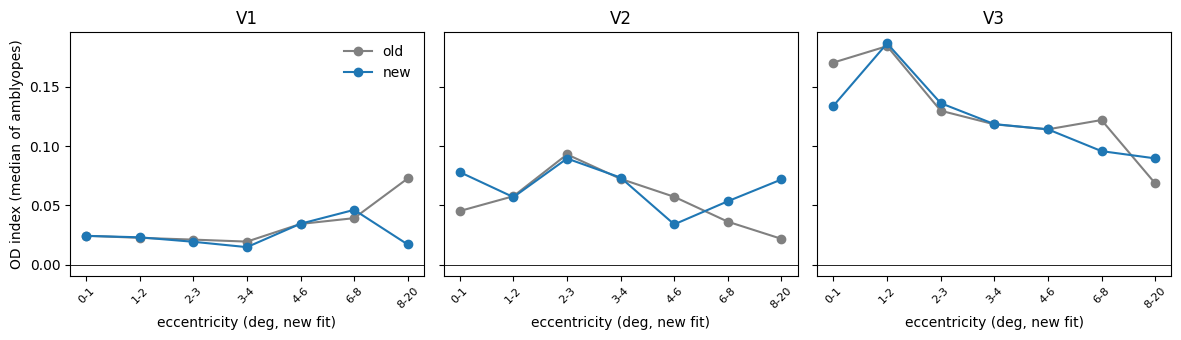

In [8]:
ecc_bins = [0, 1, 2, 3, 4, 6, 8, 20]
rows4 = []
for subject in [s for s in data if s in patients]:
    fe, ae = fe_ae(subject)
    ecc = np.nanmean([data[subject]['new']['d']['L']['prf_ecc'], data[subject]['new']['d']['R']['prf_ecc']], axis=0)
    for v in versions:
        D = data[subject][v]
        for roi in ['V1', 'V2', 'V3']:
            for b0, b1 in zip(ecc_bins[:-1], ecc_bins[1:]):
                m = D['rois'][roi] & D['keep'] & (ecc >= b0) & (ecc < b1)
                if m.sum() < 10:
                    continue
                w = D['w'][m]
                rows4.append({'subject': subject, 'version': v, 'roi': roi, 'ecc': '{}-{}'.format(b0, b1),
                              'od': wmedian(od_index(D['beta'][fe][m], D['beta'][ae][m]), w),
                              'weight share': w.sum()})
d4 = pd.DataFrame(rows4)
tot = d4.groupby(['subject', 'version', 'roi'])['weight share'].transform('sum')
d4['weight share'] = 100 * d4['weight share'] / tot
order = ['{}-{}'.format(a, b) for a, b in zip(ecc_bins[:-1], ecc_bins[1:])]
for roi in ['V1', 'V2', 'V3']:
    t = d4[d4.roi == roi].groupby(['ecc', 'version'])[['od', 'weight share']].median().unstack('version').reindex(order)
    print('\n{}: median over amblyopes (OD index, % of the ROI weight in each eccentricity bin)'.format(roi))
    print(t.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, roi in zip(axes, ['V1', 'V2', 'V3']):
    for v, col in [('old', 'grey'), ('new', 'tab:blue')]:
        t = d4[(d4.roi == roi) & (d4.version == v)].groupby('ecc')['od'].median().reindex(order)
        ax.plot(range(len(order)), t.values, '-o', color=col, label=v)
    ax.axhline(0, color='k', lw=0.6)
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=45, fontsize=8)
    ax.set_title(roi); ax.set_xlabel('eccentricity (deg, new fit)')
axes[0].set_ylabel('OD index (median of amblyopes)')
axes[0].legend(frameon=False)
plt.tight_layout()
fig.savefig('{}/od_change_eccentricity.pdf'.format(fig_dir), bbox_inches='tight')
plt.show()

## 5. Amblyopes without fellow-eye dominance in V1 (new fits)

Amblyopes without clear FE dominance in V1 (new): ['sub-01', 'sub-04', 'sub-05', 'sub-06', 'sub-10', 'sub-11']

=== sub-01 (amblyopic eye: R)
roi  pref old  pref new  od old  od new  n sel-old  n sel-new  rsq_fe new  rsq_ae new
 V1    57.375    56.407   0.013   0.012       7446       8611       0.116       0.151
 V2    59.328    59.046   0.018   0.017       5364       6144       0.198       0.245
 V3    63.807    62.971   0.028   0.027       3661       3987       0.467       0.460
 V4    63.094    63.315   0.024   0.025       2783       2826       0.509       0.480
V3A    81.087    81.028   0.038   0.038       1310       1401       0.541       0.496
V3B    73.639    74.264   0.047   0.048        704        724       0.394       0.330
LO1    69.267    68.996   0.070   0.067        487        544       0.242       0.239
LO2    27.020    27.975  -0.050  -0.051        530        543       0.251       0.233

=== sub-04 (amblyopic eye: L)
roi  pref old  pref new  od old  od new  n sel-old  n

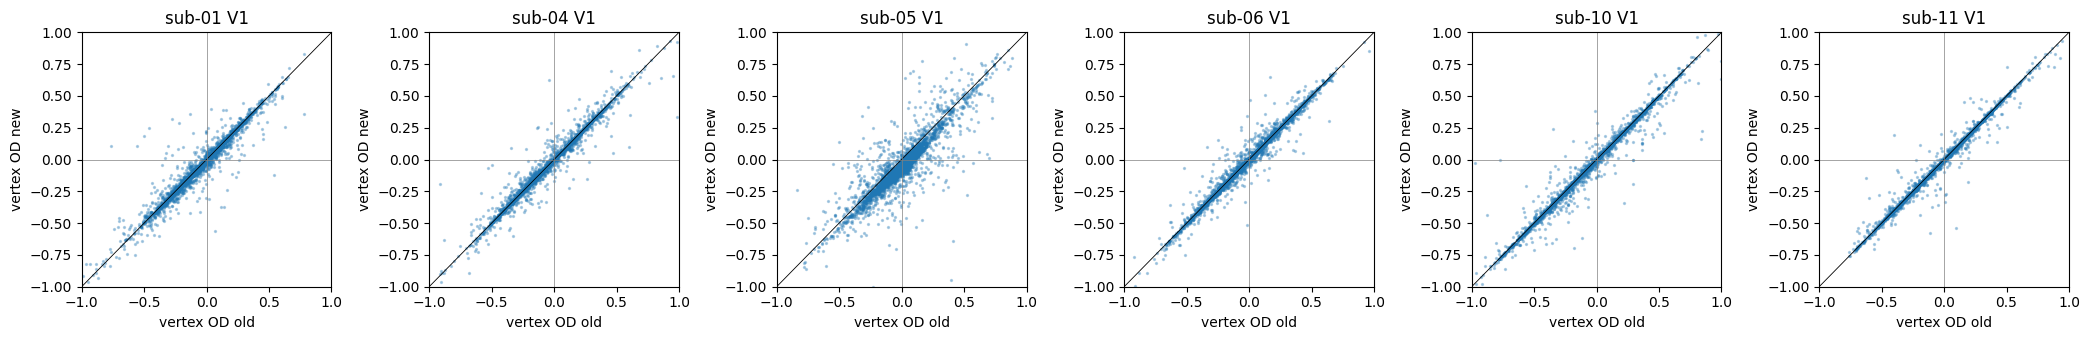

In [9]:
v1 = df[(df.group == 'patient') & (df.roi == 'V1')]
weak = v1[(v1['pref new'] < 55) | (v1['od new'] < 0.02)].subject.tolist()
print('Amblyopes without clear FE dominance in V1 (new):', weak)
for subject in weak:
    fe, ae = fe_ae(subject)
    print('\n=== {} (amblyopic eye: {})'.format(subject, ae))
    print(df[df.subject == subject][['roi', 'pref old', 'pref new', 'od old', 'od new', 'n sel-old', 'n sel-new',
                                     'rsq_fe new', 'rsq_ae new']].round(3).to_string(index=False))

fig, axes = plt.subplots(1, max(len(weak), 1), figsize=(3.5 * max(len(weak), 1), 3.5), squeeze=False)
for ax, subject in zip(axes[0], weak):
    fe, ae = fe_ae(subject)
    O, N = data[subject]['old'], data[subject]['new']
    m = O['rois']['V1'] & O['keep'] & N['keep']
    o, n = od_index(O['beta'][fe][m], O['beta'][ae][m]), od_index(N['beta'][fe][m], N['beta'][ae][m])
    ax.scatter(o, n, s=2, alpha=0.3)
    ax.plot([-1, 1], [-1, 1], 'k', lw=0.6); ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1)
    ax.set_title('{} V1'.format(subject)); ax.set_xlabel('vertex OD old'); ax.set_ylabel('vertex OD new')
plt.tight_layout()
fig.savefig('{}/od_change_weak_subjects_V1.pdf'.format(fig_dir), bbox_inches='tight')
plt.show()